

# **Property Price Prediction (House Price Estimation)**

# **Problem Statement**

Property prices are influenced by multiple factors such as house size, location, age, and overall condition. Accurately estimating property prices is important for buyers, sellers, real estate companies, and financial institutions. Manual estimation often leads to incorrect pricing and poor decision-making

The objective of this project is to build a **regression-based machine learning model** to predict property prices using historical housing data and to identify the most important factors influencing house prices.



# **Objectives of the Project**

* Understand property price patterns

* Perform basic data preprocessing

* Conduct minimal but meaningful Exploratory Data Analysis (EDA)

* Build regression-based machine learning models

* Evaluate model performance using regression metrics

* Identify key price-influencing features

In [ ]:
#uploade file
from google.colab import files
uploaded= files.upload()

Saving train 2.csv to train 2.csv


Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor


Load and read the file

In [ ]:
df=pd.read_csv("train 2.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
import pandas as pd
df = pd.read_csv("train 2.csv")
df=df[
    ['GrLivArea','Neighborhood','YearBuilt','OverallQual','BedroomAbvGr','FullBath','SalePrice']
]
df.dropna(inplace=True)

In [ ]:
df.isnull().sum()
df.info()


<class 'pandas.core.series.Series'>
RangeIndex: 1460 entries, 0 to 1459
Series name: SalePrice
Non-Null Count  Dtype
--------------  -----
1460 non-null   int64
dtypes: int64(1)
memory usage: 11.5 KB


In [ ]:
x = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

ValueError: No axis named 1 for object type Series

In [ ]:
categorical_cols=['Neighborhood']
numeric_cols=['GrLivArea','YearBuilt','OverallQual','BedroomAbvGr','FullBath']

In [ ]:
#preprocessing(Encoding+Scaling)
prprocessor=ColumnTransformer(
    transformers=[
        ('num',StandardScaler(),numeric_cols),
        ('cat',OneHotEncoder(drop='first'),categorical_cols)
    ]
)

In [ ]:
#Train-Test-Split
x_train,x_test,y_train,y_test=train_test_split(
    x,y,
    test_size=0.20,
    random_state=42
)

In [ ]:
#train Models
model={
    'Linear Regression':LinearRegression(),
    'Decision Tree':DecisionTreeRegressor(random_state=42),
    'Random Forest':RandomForestRegressor(random_state=42)
}
results={}

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

for name, model_obj in model.items():
  pipeline=Pipeline([
      ('preprocessor',prprocessor),
      ('model',model_obj)
  ])

  pipeline.fit(x_train,y_train)
  y_pred=pipeline.predict(x_test)

  rmse=np.sqrt(mean_squared_error(y_test,y_pred))
  r2=r2_score(y_test,y_pred)

  results[name] =(rmse,r2)

In [ ]:
#model Evaluation Output
for model,values in results.items():
  print(f"{model}")
  print(f"RMSE:{values[0]:.2f}")
  print(f'R^2 score:{values[1]:.2f}')
  print("-"*30)

Linear Regression
RMSE:37883.03
R^2 score:0.81
------------------------------
Decision Tree
RMSE:42459.82
R^2 score:0.76
------------------------------
Random Forest
RMSE:29837.46
R^2 score:0.88
------------------------------


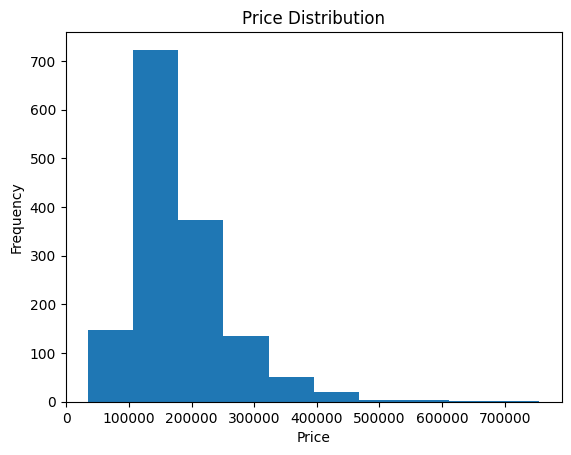

In [ ]:
#Price Distribution
plt.hist(y)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title("Price Distribution")
plt.show()

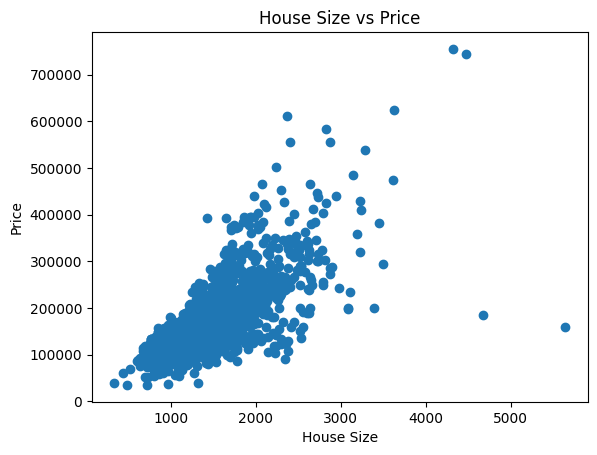

In [ ]:
#House Size vs Price
plt.scatter(x['GrLivArea'],y)
plt.xlabel('House Size')
plt.ylabel('Price')
plt.title('House Size vs Price')
plt.show()

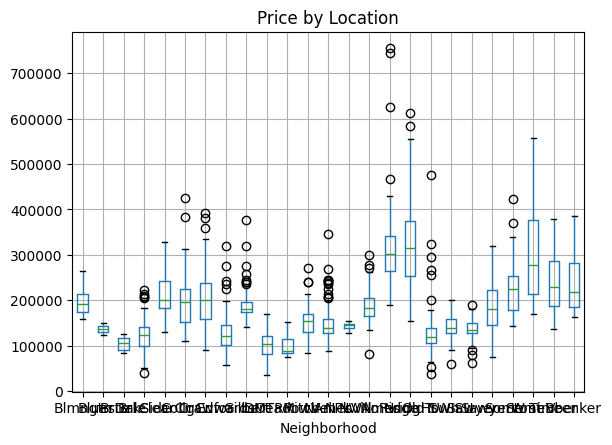

In [ ]:
#Price by Location
import pandas as pd
plot_df = pd.DataFrame({'SalePrice': y, 'Neighborhood': x['Neighborhood']})
plot_df.boxplot(column='SalePrice',by='Neighborhood')
plt.title("Price by Location")
plt.suptitle("")
plt.show()

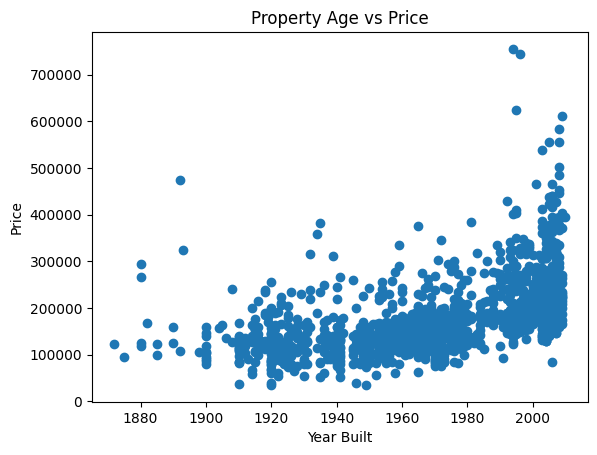

In [ ]:
#Property Age vs Prices
plt.scatter(x['YearBuilt'],y)
plt.xlabel("Year Built")
plt.ylabel("Price")
plt.title("Property Age vs Price")
plt.show()

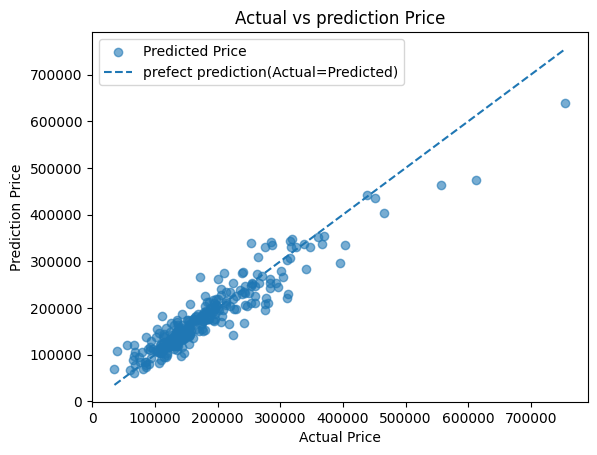

In [ ]:
# Actual Price vs Predicted Priece(Random Forest)
import matplotlib.pyplot as plt
import numpy as np

plt.figure()

#sctter plot for predictions
plt.scatter(
    y_test,y_pred,
    alpha=0.6,
    label="Predicted Price"
)


#ideal line (Actual =Predicted)

plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()],
    linestyle='--',
    label="prefect prediction(Actual=Predicted)"
)


plt.xlabel("Actual Price")
plt.ylabel("Prediction Price")
plt.title("Actual vs prediction Price")
plt.legend()
plt.show()

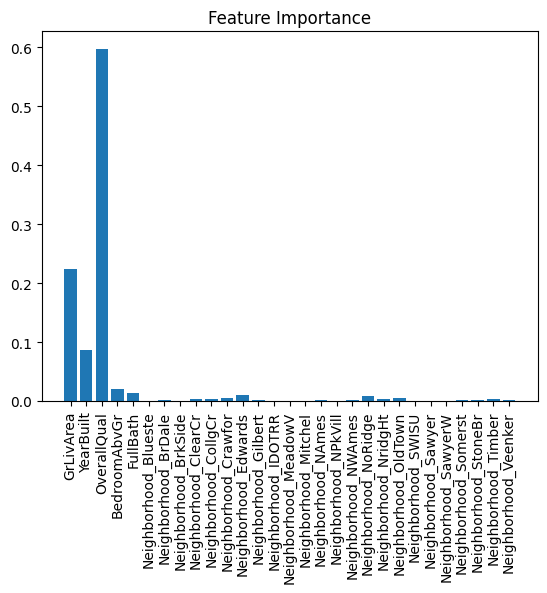

In [ ]:
# To address NameError: name 'rf_pipeline' is not defined,
# we reconstruct the Random Forest pipeline since the original 'model' dictionary
# might have been overwritten and the 'pipeline' variable was local to the training loop.
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Re-initialize the RandomForestRegressor object
rf_regressor = RandomForestRegressor(random_state=42)

# Construct the Random Forest pipeline using the existing preprocessor and the new regressor
rf_pipeline = Pipeline([
    ('preprocessor', prprocessor), # 'prprocessor' (ColumnTransformer object) is already defined
    ('model', rf_regressor)
])

# Fit the pipeline using the existing x_train and y_train data
rf_pipeline.fit(x_train, y_train)

# Now proceed with feature importance calculation
rf_model = rf_pipeline.named_steps['model']
feature_names = (
    numeric_cols +
    list(
        rf_pipeline.named_steps['preprocessor'] # Corrected 'Preprocessor' to 'preprocessor'
        .named_transformers_['cat']
        .get_feature_names_out(categorical_cols)
    )
)
plt.bar(feature_names, rf_model.feature_importances_)
plt.xticks(rotation=90)
plt.title("Feature Importance")
plt.show()